# The symmetric 0-pi qubit (notes Appendix B.2)

Each step follows the notes; equation labels are given in comments.

In [1]:
import sympy as sym
import circuit_quantization as cq
from circuit_quantization import Branch, Circuit, Loops, quantize

sym.init_printing()
F, H, W = cq.ghz_to_farad, cq.ghz_to_henry, cq.phase_to_weber

In [2]:
CJ, C, L, EJ = sym.symbols("C_J C L E_J", positive=True)
circuit = Circuit([
    Branch("J1", 1, 2, C=CJ, EJ=EJ),
    Branch("J2", 3, 4, C=CJ, EJ=EJ),
    Branch("L1", 2, 3, L=L),
    Branch("L2", 4, 1, L=L),
    Branch("C1", 1, 3, C=C),
    Branch("C2", 2, 4, C=C),
])  # floating: no ground
cycles = {  # eq:zp_G
    "ring": {"J1": 1, "J2": 1, "L1": 1, "L2": 1},
    "t1": {"J1": 1, "L1": 1, "C1": -1},
    "t2": {"J2": 1, "L1": 1, "C2": -1},
}
loops = Loops.from_branch_dict(circuit, cycles, {"t1": 0, "t2": 0})
Z = sym.Matrix([[-1, -1, 1, 1], [1, 1, 1, 1], [-1, 1, -1, 1], [1, -1, -1, 1]]) / 2  # eq:zp_Z
res = quantize(circuit, loops, Z, ("e", "c", "h", "cy"), simplify=True)
res

Result(circuit=Circuit(branches=(Branch(name='C1', tail=1, head=3, C=C, L=None, EJ=None, V=None, energy_symbols=False), Branch(name='C2', tail=2, head=4, C=C, L=None, EJ=None, V=None, energy_symbols=False), Branch(name='J1', tail=1, head=2, C=C_J, L=None, EJ=E_J, V=None, energy_symbols=False), Branch(name='J2', tail=3, head=4, C=C_J, L=None, EJ=E_J, V=None, energy_symbols=False), Branch(name='L1', tail=2, head=3, C=0, L=L, EJ=None, V=None, energy_symbols=False), Branch(name='L2', tail=4, head=1, C=0, L=L, EJ=None, V=None, energy_symbols=False)), ground=None, t=t), loops=Loops(circuit=Circuit(branches=(Branch(name='C1', tail=1, head=3, C=C, L=None, EJ=None, V=None, energy_symbols=False), Branch(name='C2', tail=2, head=4, C=C, L=None, EJ=None, V=None, energy_symbols=False), Branch(name='J1', tail=1, head=2, C=C_J, L=None, EJ=E_J, V=None, energy_symbols=False), Branch(name='J2', tail=3, head=4, C=C_J, L=None, EJ=E_J, V=None, energy_symbols=False), Branch(name='L1', tail=2, head=3, C=0, L=

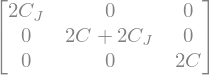

In [3]:
res.coords.C_tilde

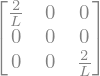

In [4]:
res.coords.Lstar_tilde

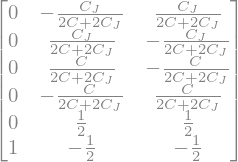

In [5]:
res.B

## Asymmetric 0-π

With every element distinct the symmetry no longer decouples the modes: in the automatic basis
$\tilde C$ couples the compact mode to both others, and $\tilde L^*$ couples the extended and harmonic modes.
Below, two choices of the residual transformation $S_1$: sircuitenum's, and symbolic normal modes.

In [6]:
CJ1, CJ2, C1, C2, L1, L2, EJ1, EJ2 = sym.symbols("C_J1 C_J2 C_1 C_2 L_1 L_2 E_J1 E_J2", positive=True)
circuit_a = Circuit([
    Branch("J1", 1, 2, C=CJ1, EJ=EJ1),
    Branch("J2", 3, 4, C=CJ2, EJ=EJ2),
    Branch("L1", 2, 3, L=L1),
    Branch("L2", 4, 1, L=L2),
    Branch("C1", 1, 3, C=C1),
    Branch("C2", 2, 4, C=C2),
])
loops_a = Loops.from_branch_dict(circuit_a, cycles, {"t1": 0, "t2": 0})
res_a = quantize(circuit_a, loops_a)  # automatic basis
res_a.coords.types, res_a.coords.C_tilde, res_a.coords.Lstar_tilde

(('c', 'e', 'h'),
 Matrix([
 [C_1 + C_2 + C_J1 + C_J2, -2*C_J1 + 2*C_J2, -2*C_1 + 2*C_2],
 [       -2*C_J1 + 2*C_J2,  4*C_J1 + 4*C_J2,              0],
 [         -2*C_1 + 2*C_2,                0,  4*C_1 + 4*C_2]]),
 Matrix([
 [0,                         0,                         0],
 [0, (4*L_1 + 4*L_2)/(L_1*L_2), (4*L_1 - 4*L_2)/(L_1*L_2)],
 [0, (4*L_1 - 4*L_2)/(L_1*L_2), (4*L_1 + 4*L_2)/(L_1*L_2)]]))

### sircuitenum's choice

The default `choose_S1` reproduces sircuitenum: compact alignments, junction couplings then inductive and charging
couplings zeroed with Singular, ranked by its H_hash; `choose_instance` then picks integer junction coefficients with z3.

In [7]:
from circuit_quantization.optimize import choose_instance, choose_S1

S1s_se, h_class = choose_S1(res_a.lag, res_a.coords)
S_se, weight = choose_instance(res_a.lag, res_a.coords, S1s_se[0])
res_se = res_a.transform(S_se, simplify=True)
h_class, weight, res_se.coords.types, res_se.coords.omega_J_tilde.T

(('111', '1-100', 4, '1-001', '3-111'),
 3,
 ('c', 'e', 'h'),
 Matrix([
 [ 1, 1, 0],
 [-1, 0, 0]]))

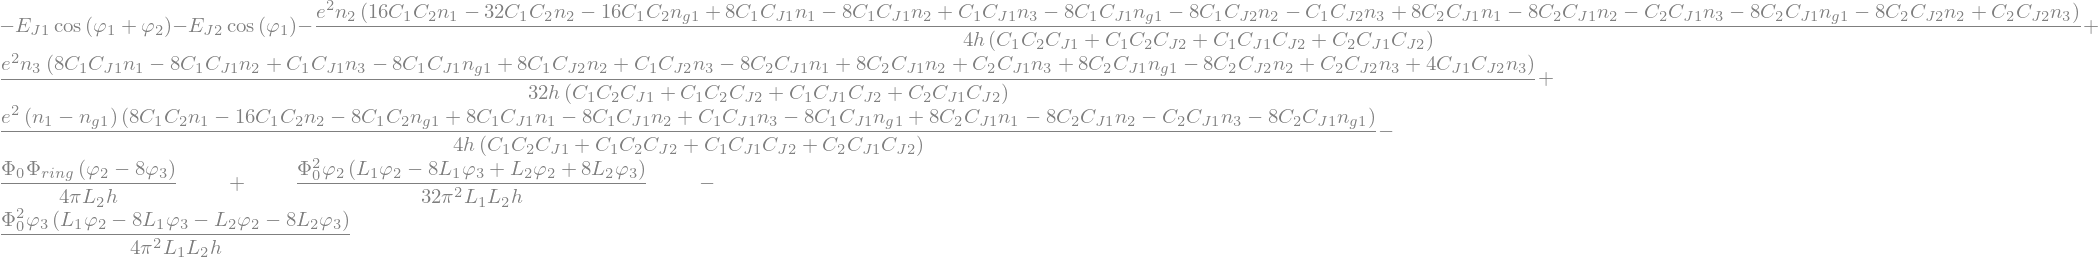

In [8]:
res_se.H

### Symbolic normal modes

With two noncompact modes the generalized eigenvalues of $L^* x = \lambda C x$ involve a single square root,
so `normal_mode_decoupling` stays symbolic. It returns $S_1$ together with the diagonal $\tilde C$ and $\tilde L^*$
the construction guarantees, which `transform` uses instead of re-simplifying the radicals.
Mixing the extended and harmonic modes makes both extended.

In [9]:
S_nm, C_nm, L_nm = cq.normal_mode_decoupling(res_a.lag, res_a.coords)
coords_nm = cq.transform(res_a.lag, res_a.coords, S_nm, C_tilde=C_nm, Lstar_tilde=L_nm)
nonzero = lambda M: M.applyfunc(lambda x: int(sym.cancel(x) != 0))
coords_nm.types, nonzero(coords_nm.C_tilde), nonzero(coords_nm.Lstar_tilde)

(('c', 'e', 'e'),
 Matrix([
 [1, 0, 0],
 [0, 1, 0],
 [0, 0, 1]]),
 Matrix([
 [0, 0, 0],
 [0, 1, 0],
 [0, 0, 1]]))

In [13]:
coords_nm.C_tilde

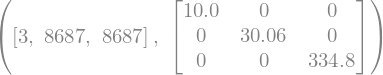

In [10]:
# Exact but large: operation counts of the new diagonal capacitances, and the normal-mode C~ at sample values
values = {CJ1: 1, CJ2: 2, C1: 3, C2: 4, L1: 1, L2: 2}
[sym.count_ops(coords_nm.C_tilde[i, i]) for i in range(3)], cq.numerify(coords_nm, values).C_tilde.evalf(4)

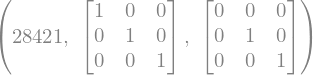

In [11]:
# B is unchanged by any S_1, so the Hamiltonian reuses res_a.B
ham_nm = cq.hamiltonian(res_a.lag, coords_nm, res_a.loops, res_a.B, circuit_a.t)
sym.count_ops(ham_nm.H), nonzero(ham_nm.E_C), nonzero(ham_nm.E_L)